# DX799 O1 - Week 5 Jupyter Notebook: Support Vector Machines

## Digital Customer Journey and E-Commerce Retention Analytics

**Student:** Javed Aamer

### Goal

Week 5 asks whether a straight classification boundary is enough, or whether a more flexible support vector machine can separate the classes better. I keep the same four binary decisions from Week 4 so the comparison is meaningful across the customer journey.

- **Behavior:** added to cart or not
- **Churn:** churned or stayed
- **Products:** high recent demand or not
- **Reviews:** higher sentiment or not

The notebook covers the Week 5 concepts directly: decision boundary, margin, support vectors, linear and nonlinear kernels, the kernel trick, feature scaling, and regularization through `C`.

I use all four datasets for breadth, but I treat **Churn as the Week 5 depth example** because retention is the strongest decision problem in the project and the original Week 5 work already showed a meaningful nonlinear gain.

## 1. Questions I want to answer

1. Does a nonlinear kernel improve classification over a linear SVM?
2. Do the four customer-journey datasets need the same type of boundary?
3. How does `C` change the tradeoff between margin size and classification errors?
4. What share of the training data becomes support vectors?
5. For Churn, does tuning polynomial degree and RBF `gamma` produce a meaningful gain?
6. Is the gain large enough to justify the loss of interpretability from a nonlinear model?

The test sets remain untouched until kernel and regularization choices are fixed.

## 2. Week 5 concepts from the lecture

### Decision boundary and margin

An SVM places a separating hyperplane between the classes. The observations closest to that boundary are the **support vectors**. They determine where the boundary sits. A wider margin can improve generalization when the classes are reasonably separable.

### Kernel trick

A linear kernel creates a flat boundary in the transformed feature space. A polynomial kernel allows combinations of predictors to create a curved boundary in the original space. The Gaussian or RBF kernel can create even more flexible local boundaries without explicitly generating all of those transformed coordinates.

### Regularization with `C`

`C` controls the tradeoff between two goals:

- a wider margin with more tolerated violations
- fewer training errors with a tighter boundary

Smaller `C` allows more violations and usually favors a wider margin. Larger `C` penalizes violations more strongly.

### Why scaling matters

SVM margins are based on distances and inner products. I standardize numeric features so variables measured in large units do not dominate those calculations simply because of scale.

In [1]:
from pathlib import Path
import re
import json
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 3. Load the four cleaned datasets

The data architecture is unchanged from the previous weeks. Products and reviews can be related through ASIN when needed. Behavior and churn do not share a verified customer key, so I preserve their valid grains rather than force-joining them.

In [2]:
candidate_dirs = [
    Path("data"),
    Path("../data"),
    Path("data_pkg"),
    Path("../data_pkg"),
    Path("/mnt/data/dx799_rebuild/data/cleaned_week2_output"),
]

DATA_DIR = next(
    (p for p in candidate_dirs if (p / "behavior_clean.csv").exists()),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not find the four cleaned CSV files.")

behavior = pd.read_csv(DATA_DIR / "behavior_clean.csv", low_memory=False)
churn = pd.read_csv(DATA_DIR / "churn_clean.csv", low_memory=False)
products = pd.read_csv(DATA_DIR / "products_clean.csv", low_memory=False)
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", low_memory=False)

print(f"Loaded data from: {DATA_DIR}")

Loaded data from: /mnt/data/dx799_rebuild/data/cleaned_week2_output


In [3]:
# Parse the product and review fields used by the Week 5 classifiers.

products["rating_stars_num"] = pd.to_numeric(
    products["rating_stars"].astype(str).str.extract(r"([0-9.]+)")[0],
    errors="coerce",
)

products["rating_count_num"] = pd.to_numeric(
    products["rating_count"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+)")[0],
    errors="coerce",
)

def parse_recent_purchases(value):
    match = re.search(r"([\d,.]+)\s*([Kk]?)", str(value))
    if not match:
        return np.nan
    number = float(match.group(1).replace(",", ""))
    return number * 1000 if match.group(2) else number

products["recent_purchases_num"] = products["recent_purchases"].map(parse_recent_purchases)
products["list_price_num"] = pd.to_numeric(
    products["list_price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"\$([0-9.]+)")[0],
    errors="coerce",
)
products["discount_pct"] = np.where(
    products["list_price_num"] > 0,
    (products["list_price_num"] - products["price_value"]) / products["list_price_num"],
    0,
)
products["main_rank"] = pd.to_numeric(
    products["best_sellers_rank"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"#([0-9]+)")[0],
    errors="coerce",
)
products["in_stock"] = (
    products["availability"].astype(str).str.lower().str.contains("in stock").astype(int)
)
products["description_len"] = products["product_description"].astype(str).str.len()
products["review_summary_len"] = products["customer_review_summary"].astype(str).str.len()
products["high_demand"] = (products["recent_purchases_num"] >= 300).astype(int)

reviews["review_len"] = reviews["cleaned_review_text"].astype(str).str.split().str.len()
reviews["verified_int"] = reviews["verifiedPurchase"].astype(int)
reviews["high_sentiment"] = (reviews["sentiment_score"] > 0.30).astype(int)

In [4]:
CLS_TASKS = {
    "Behavior": {
        "df": behavior,
        "target": "Add to Cart",
        "group": "Customer ID",
        "numeric": [
            "Browsing Time (min)", "Sales", "Quantity", "Discount", "Age"
        ],
        "categorical": [
            "Segment", "Ship Mode", "Product Category", "Order Priority", "Like", "Share"
        ],
    },
    "Churn": {
        "df": churn,
        "target": "Churn",
        "group": None,
        "numeric": [
            "Tenure", "WarehouseToHome", "HourSpendOnApp",
            "NumberOfDeviceRegistered", "SatisfactionScore",
            "NumberOfAddress", "Complain", "OrderAmountHikeFromlastYear",
            "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount"
        ],
        "categorical": [
            "PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat",
            "MaritalStatus", "CityTier", "Gender"
        ],
    },
    "Products": {
        "df": products,
        "target": "high_demand",
        "group": None,
        "numeric": [
            "price_value", "rating_stars_num", "rating_count_num", "discount_pct",
            "main_rank", "rank_1", "description_len", "review_summary_len"
        ],
        "categorical": ["in_stock"],
    },
    "Reviews": {
        "df": reviews,
        "target": "high_sentiment",
        "group": "productASIN",
        "numeric": [
            "rating", "helpfulVoteCount", "reviewPosition", "review_len", "verified_int"
        ],
        "categorical": [],
    },
}

role_table = pd.DataFrame({
    "Dataset": ["Behavior", "Churn", "Products", "Reviews"],
    "Rows": [len(behavior), len(churn), len(products), len(reviews)],
    "Grain": ["order/activity", "customer", "product", "review"],
    "Positive outcome": [
        "Added to cart", "Churned", "High recent demand", "Sentiment > 0.30"
    ],
})

display(role_table)

,Dataset,Rows,Grain,Positive outcome
0,Behavior,51289,order/activity,Added to cart
1,Churn,5630,customer,Churned
2,Products,728,product,High recent demand
3,Reviews,6327,review,Sentiment > 0.30


## 4. Class balance and why the evaluation metric changes

Churn is the clearest minority-class problem. I therefore use **PR-AUC** as the main validation metric for Churn. For Behavior, Products, and Reviews I use **ROC-AUC** for kernel selection because their classes are more balanced.

I still report both ROC-AUC and PR-AUC for every final model.

,Dataset,Positive prevalence,Positive rows,Negative rows
0,Behavior,0.6667,34196,17093
1,Churn,0.1684,948,4682
2,Products,0.4574,333,395
3,Reviews,0.4990,3157,3170


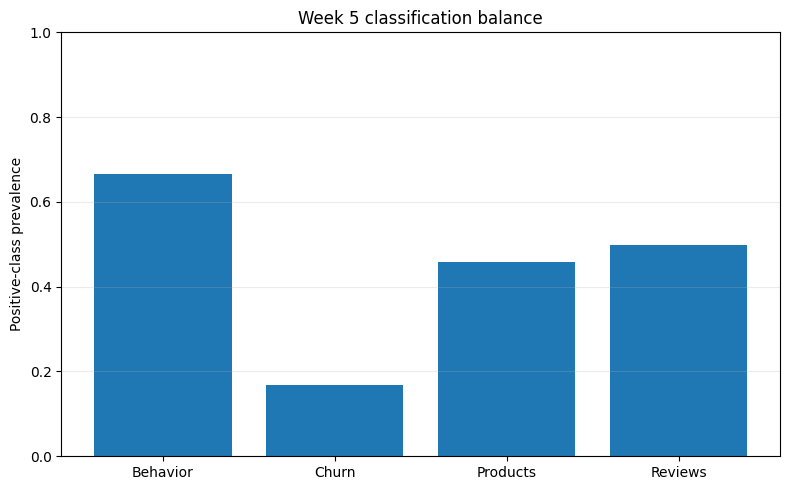

In [5]:
balance_rows = []
for name, task in CLS_TASKS.items():
    y = task["df"][task["target"]].astype(int)
    balance_rows.append({
        "Dataset": name,
        "Positive prevalence": y.mean(),
        "Positive rows": int((y == 1).sum()),
        "Negative rows": int((y == 0).sum()),
    })

class_balance = pd.DataFrame(balance_rows)
display(class_balance.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(class_balance["Dataset"], class_balance["Positive prevalence"])
ax.set_ylim(0, 1)
ax.set_ylabel("Positive-class prevalence")
ax.set_title("Week 5 classification balance")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Split and preprocessing strategy

- Churn and Products use target-stratified train, validation, and test splits.
- Behavior is split by `Customer ID`.
- Reviews are split by `productASIN`.
- Numeric predictors are median-imputed and standardized.
- Categorical predictors are imputed and one-hot encoded.

Kernel SVM training cost rises quickly with sample size. After the leakage-safe split, I therefore cap the larger Behavior, Churn, and Reviews partitions for the Week 5 SVM experiments. The cap is applied **inside each existing partition**, so it does not allow customers or products to cross train, validation, and test boundaries. Products are small enough to use in full.

In [6]:
def split_three(df, target, group_col=None):
    idx = np.arange(len(df))

    if group_col is not None:
        groups = df[group_col].astype(str).values

        first = GroupShuffleSplit(
            n_splits=1, test_size=0.20, random_state=RANDOM_STATE
        )
        train_validation, test = next(first.split(idx, groups=groups))

        second = GroupShuffleSplit(
            n_splits=1, test_size=0.25, random_state=RANDOM_STATE + 1
        )
        train_relative, validation_relative = next(
            second.split(train_validation, groups=groups[train_validation])
        )

        train = train_validation[train_relative]
        validation = train_validation[validation_relative]

    else:
        y = df[target].astype(int).values
        train_validation, test = train_test_split(
            idx, test_size=0.20, random_state=RANDOM_STATE, stratify=y
        )
        train, validation = train_test_split(
            train_validation,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
            stratify=y[train_validation],
        )

    return train, validation, test

def cap_partition(idx, y, nmax, seed):
    if len(idx) <= nmax:
        return idx
    chosen, _ = train_test_split(
        np.arange(len(idx)),
        train_size=nmax,
        random_state=seed,
        stratify=y[idx],
    )
    return idx[chosen]

def make_preprocessor(task):
    transformers = []

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    transformers.append(("numeric", numeric_pipe, task["numeric"]))

    if task["categorical"]:
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ])
        transformers.append(("categorical", categorical_pipe, task["categorical"]))

    return ColumnTransformer(transformers)

def class_metrics(y_true, score, prediction):
    return {
        "ROC_AUC": roc_auc_score(y_true, score),
        "PR_AUC": average_precision_score(y_true, score),
        "Accuracy": accuracy_score(y_true, prediction),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
    }

## 6. Broad kernel comparison across all four datasets

For breadth, I compare four boundary shapes at the same moderate regularization setting, `C = 1`.

- **Linear**
- **Polynomial degree 2**
- **Polynomial degree 3**
- **RBF with the default scale-based gamma**

I deliberately keep the broad comparison simple. The point is to ask whether boundary shape matters across the four parts of the project. I reserve the heavier `C`, degree, and `gamma` tuning for the Churn depth analysis rather than repeating the same grid search four times.

In [7]:
broad_rows = []
partition_store = {}

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]
    y_all = df[task["target"]].astype(int).values

    train_idx, validation_idx, test_idx = split_three(
        df, task["target"], task["group"]
    )

    cap_map = {
        "Behavior": (2500, 900, 1400),
        "Churn": (2500, 900, 1100),
        "Reviews": (2500, 900, 1200),
    }
    if dataset_name in cap_map:
        n_train, n_val, n_test = cap_map[dataset_name]
        train_idx = cap_partition(train_idx, y_all, n_train, 42)
        validation_idx = cap_partition(validation_idx, y_all, n_val, 43)
        test_idx = cap_partition(test_idx, y_all, n_test, 44)

    preprocessor = make_preprocessor(task)
    X_train = preprocessor.fit_transform(df.iloc[train_idx])
    X_validation = preprocessor.transform(df.iloc[validation_idx])
    X_test = preprocessor.transform(df.iloc[test_idx])

    y_train = y_all[train_idx]
    y_validation = y_all[validation_idx]
    y_test = y_all[test_idx]

    partition_store[dataset_name] = {
        "train_idx": train_idx,
        "validation_idx": validation_idx,
        "test_idx": test_idx,
        "preprocessor": preprocessor,
        "X_train": X_train,
        "X_validation": X_validation,
        "X_test": X_test,
        "y_train": y_train,
        "y_validation": y_validation,
        "y_test": y_test,
    }

    class_weight = "balanced" if dataset_name == "Churn" else None
    tuning_metric = "PR_AUC" if dataset_name == "Churn" else "ROC_AUC"

    specs = [
        ("Linear", dict(kernel="linear", C=1.0)),
        ("Polynomial d=2", dict(kernel="poly", C=1.0, degree=2, gamma="scale")),
        ("Polynomial d=3", dict(kernel="poly", C=1.0, degree=3, gamma="scale")),
        ("RBF", dict(kernel="rbf", C=1.0, gamma="scale")),
    ]

    for label, params in specs:
        model = SVC(
            class_weight=class_weight,
            **params,
        )
        model.fit(X_train, y_train)
        score = model.decision_function(X_validation)
        prediction = model.predict(X_validation)
        metrics = class_metrics(y_validation, score, prediction)

        broad_rows.append({
            "Dataset": dataset_name,
            "Kernel": label,
            "C": 1.0,
            "Support vectors": int(model.n_support_.sum()),
            "Support-vector share": float(model.n_support_.sum() / len(y_train)),
            **metrics,
            "Tuning_metric": tuning_metric,
            "Tuning_score": metrics[tuning_metric],
        })

broad_validation = pd.DataFrame(broad_rows)
display(
    broad_validation.sort_values(["Dataset", "Tuning_score"], ascending=[True, False])
    .round(4)
)

,Dataset,Kernel,C,Support vectors,Support-vector share,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,Tuning_metric,Tuning_score
1,Behavior,Polynomial d=2,1.0000,1618,0.6472,0.7419,0.8646,0.6889,0.6454,0.7710,0.7685,0.7697,ROC_AUC,0.7419
0,Behavior,Linear,1.0000,1637,0.6548,0.7385,0.8594,0.6811,0.6621,0.7927,0.7159,0.7524,ROC_AUC,0.7385
3,Behavior,RBF,1.0000,1670,0.6680,0.7362,0.8502,0.6756,0.6104,0.7435,0.7947,0.7683,ROC_AUC,0.7362
2,Behavior,Polynomial d=3,1.0000,1640,0.6560,0.7297,0.8522,0.6478,0.5854,0.7296,0.7619,0.7454,ROC_AUC,0.7297
7,Churn,RBF,1.0000,1180,0.4720,0.9236,0.7785,0.8756,0.8697,0.5882,0.8609,0.6989,PR_AUC,0.7785
6,Churn,Polynomial d=3,1.0000,1154,0.4616,0.9265,0.7616,0.9078,0.8838,0.6809,0.8477,0.7552,PR_AUC,0.7616
5,Churn,Polynomial d=2,1.0000,1156,0.4624,0.9023,0.6988,0.8489,0.8431,0.5316,0.8344,0.6495,PR_AUC,0.6988
4,Churn,Linear,1.0000,1059,0.4236,0.8797,0.6957,0.8200,0.8178,0.4786,0.8146,0.6029,PR_AUC,0.6957
11,Products,RBF,1.0000,328,0.7523,0.6824,0.6427,0.6027,0.5910,0.5882,0.4478,0.5085,ROC_AUC,0.6824
8,Products,Linear,1.0000,308,0.7064,0.6739,0.6165,0.6233,0.6100,0.6250,0.4478,0.5217,ROC_AUC,0.6739


## 7. Validation comparison by dataset

I keep each dataset in its own chart so the vertical scale remains honest. Because `C` is held at 1 in this breadth section, the comparison isolates the **shape of the decision boundary** rather than mixing kernel choice with a full hyperparameter search.

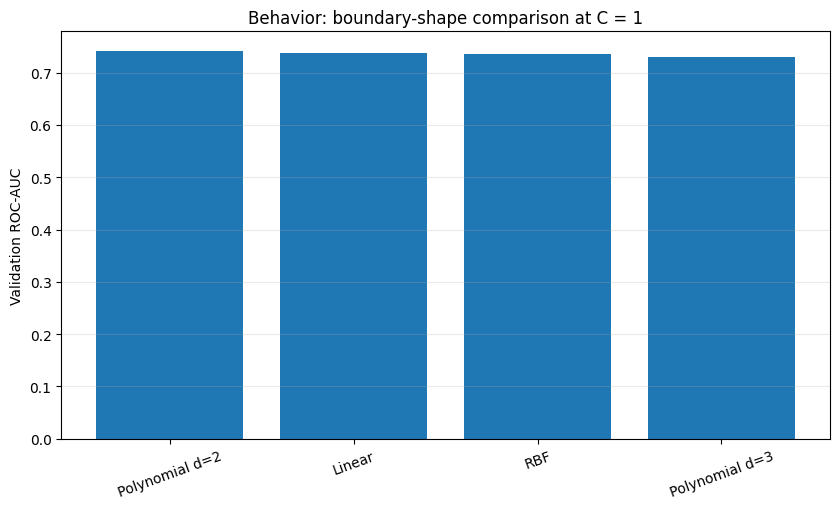

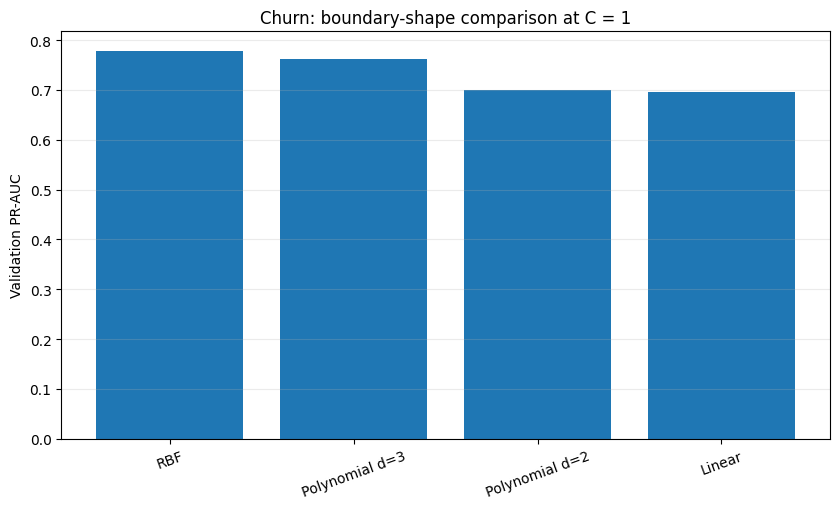

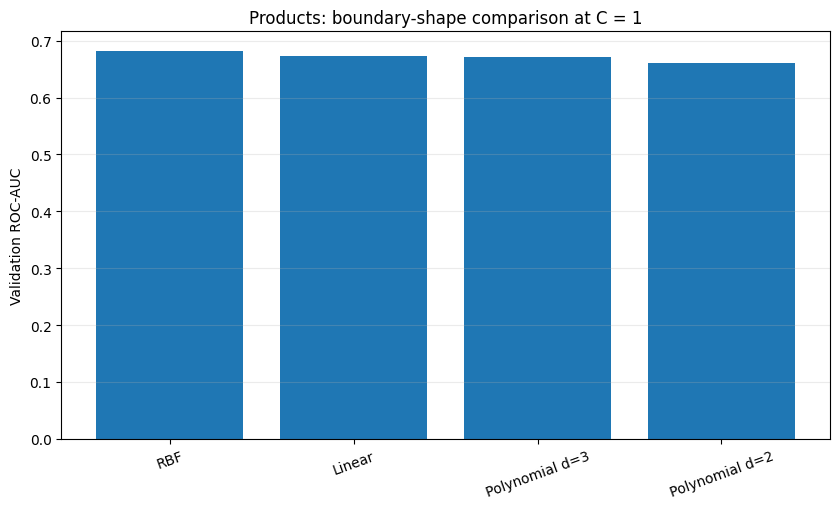

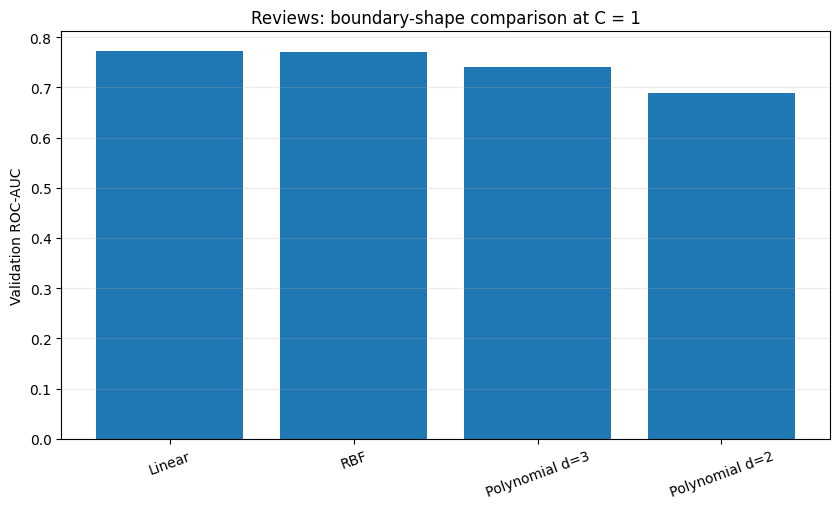

In [8]:
for dataset_name in CLS_TASKS:
    subset = broad_validation[
        broad_validation["Dataset"] == dataset_name
    ].sort_values("Tuning_score", ascending=False)

    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.bar(
        subset["Kernel"],
        subset["Tuning_score"],
    )
    ax.set_ylabel(
        "Validation PR-AUC" if dataset_name == "Churn" else "Validation ROC-AUC"
    )
    ax.set_title(f"{dataset_name}: boundary-shape comparison at C = 1")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

### Broad-comparison observation

The four datasets do not respond identically to nonlinear boundaries. That is useful because it shows that a flexible kernel should not be selected automatically.

This section tells me where nonlinearity appears promising. The heavier regularization and kernel-width tuning is concentrated on Churn, where the business value and the original Week 5 results justify a depth analysis.

## 8. Final broad comparison on the untouched test sets

For each dataset I carry the four validation-tested boundary shapes forward to the untouched test partition. This is a breadth comparison, not a full hyperparameter search.

The main question is whether the nonlinear kernels provide a meaningful final gain over the linear SVM before I invest in deeper tuning.

In [9]:
final_rows = []
final_models = {}
final_scores = {}

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]
    store = partition_store[dataset_name]
    y_all = df[task["target"]].astype(int).values

    train_validation_idx = np.concatenate([
        store["train_idx"], store["validation_idx"]
    ])
    test_idx = store["test_idx"]

    preprocessor = make_preprocessor(task)
    X_train_validation = preprocessor.fit_transform(df.iloc[train_validation_idx])
    X_test = preprocessor.transform(df.iloc[test_idx])
    y_train_validation = y_all[train_validation_idx]
    y_test = y_all[test_idx]

    class_weight = "balanced" if dataset_name == "Churn" else None

    specs = [
        ("Linear", "Linear", dict(kernel="linear", C=1.0)),
        ("Polynomial", "Polynomial d=3", dict(kernel="poly", C=1.0, degree=3, gamma="scale")),
        ("RBF", "RBF", dict(kernel="rbf", C=1.0, gamma="scale")),
    ]

    for family, label, params in specs:
        model = SVC(class_weight=class_weight, **params)
        model.fit(X_train_validation, y_train_validation)
        score = model.decision_function(X_test)
        prediction = model.predict(X_test)
        metrics = class_metrics(y_test, score, prediction)

        final_rows.append({
            "Dataset": dataset_name,
            "Family": family,
            "Chosen configuration": label,
            "C": 1.0,
            "Support vectors": int(model.n_support_.sum()),
            "Support-vector share": float(model.n_support_.sum() / len(y_train_validation)),
            **metrics,
        })

        final_models[(dataset_name, family)] = model
        final_scores[(dataset_name, family)] = (y_test, score, prediction)

final_results = pd.DataFrame(final_rows)
display(final_results.round(4))

,Dataset,Family,Chosen configuration,C,Support vectors,Support-vector share,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1
0,Behavior,Linear,Linear,1.0000,2251,0.6621,0.7465,0.8636,0.6879,0.7073,0.8453,0.6476,0.7334
1,Behavior,Polynomial,Polynomial d=3,1.0000,2195,0.6456,0.7233,0.8436,0.6693,0.6246,0.7450,0.7619,0.7533
2,Behavior,RBF,RBF,1.0000,2244,0.6600,0.7396,0.8460,0.6836,0.6333,0.7482,0.7877,0.7675
3,Churn,Linear,Linear,1.0000,1473,0.4332,0.8800,0.6750,0.8045,0.8117,0.4567,0.8226,0.5873
4,Churn,Polynomial,Polynomial d=3,1.0000,1492,0.4388,0.9277,0.7428,0.8818,0.8561,0.6129,0.8172,0.7005
5,Churn,RBF,RBF,1.0000,1553,0.4568,0.9259,0.7436,0.8709,0.8581,0.5821,0.8387,0.6872
6,Products,Linear,Linear,1.0000,427,0.7337,0.6800,0.6266,0.6370,0.6215,0.6591,0.4328,0.5225
7,Products,Polynomial,Polynomial d=3,1.0000,467,0.8024,0.6915,0.6318,0.6027,0.5762,0.6800,0.2537,0.3696
8,Products,RBF,RBF,1.0000,444,0.7629,0.6898,0.6484,0.6849,0.6760,0.6909,0.5672,0.6230
9,Reviews,Linear,Linear,1.0000,2333,0.6862,0.7631,0.7373,0.6875,0.6883,0.6545,0.7832,0.7131


,Dataset,Kernel,ROC-AUC gain vs linear
0,Behavior,Polynomial,-0.0232
1,Behavior,RBF,-0.0069
2,Churn,Polynomial,0.0477
3,Churn,RBF,0.0459
4,Products,Polynomial,0.0115
5,Products,RBF,0.0098
6,Reviews,Polynomial,-0.0283
7,Reviews,RBF,-0.0070


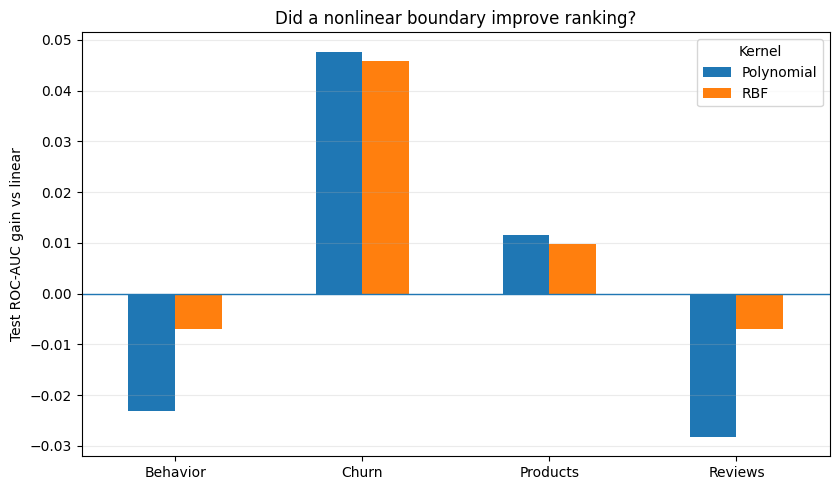

In [10]:
# Decision-useful view: nonlinear ROC-AUC improvement over the linear SVM.

gain_rows = []
for dataset_name in CLS_TASKS:
    subset = final_results[final_results["Dataset"] == dataset_name]
    linear_auc = subset.loc[subset["Family"] == "Linear", "ROC_AUC"].iloc[0]

    for family in ["Polynomial", "RBF"]:
        auc = subset.loc[subset["Family"] == family, "ROC_AUC"].iloc[0]
        gain_rows.append({
            "Dataset": dataset_name,
            "Kernel": family,
            "ROC-AUC gain vs linear": auc - linear_auc,
        })

nonlinear_gain = pd.DataFrame(gain_rows)
display(nonlinear_gain.round(4))

pivot_gain = nonlinear_gain.pivot(
    index="Dataset", columns="Kernel", values="ROC-AUC gain vs linear"
)
ax = pivot_gain.plot(kind="bar", figsize=(8.5, 5))
ax.axhline(0, linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Test ROC-AUC gain vs linear")
ax.set_title("Did a nonlinear boundary improve ranking?")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

,Dataset,Best family,Support-vector share,ROC_AUC,PR_AUC,F1
0,Behavior,Linear,0.6621,0.7465,0.8636,0.7334
1,Churn,RBF,0.4568,0.9259,0.7436,0.6872
2,Products,Polynomial,0.8024,0.6915,0.6318,0.3696
3,Reviews,Linear,0.6862,0.7631,0.7373,0.7131


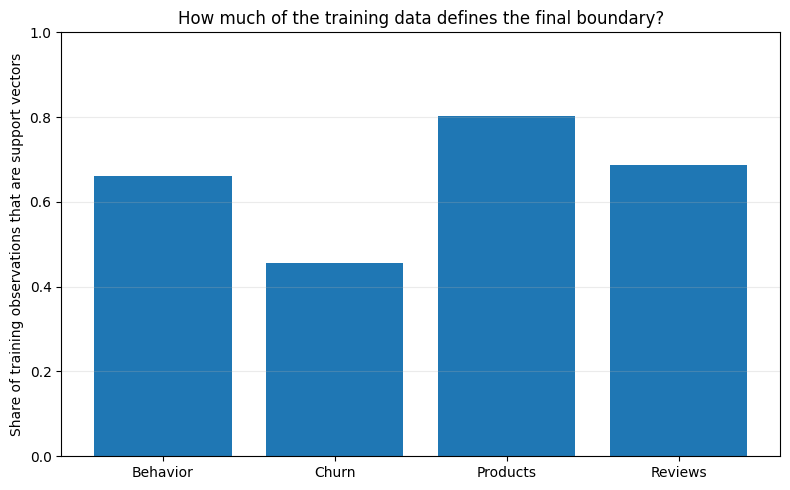

In [11]:
# Support-vector share for the best final family in each dataset.

best_family_rows = []
for dataset_name in CLS_TASKS:
    subset = final_results[final_results["Dataset"] == dataset_name].copy()
    metric = "PR_AUC" if dataset_name == "Churn" else "ROC_AUC"
    best = subset.sort_values(metric, ascending=False).iloc[0]
    best_family_rows.append({
        "Dataset": dataset_name,
        "Best family": best["Family"],
        "Support-vector share": best["Support-vector share"],
        "ROC_AUC": best["ROC_AUC"],
        "PR_AUC": best["PR_AUC"],
        "F1": best["F1"],
    })

best_family_summary = pd.DataFrame(best_family_rows)
display(best_family_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    best_family_summary["Dataset"],
    best_family_summary["Support-vector share"],
)
ax.set_ylim(0, 1)
ax.set_ylabel("Share of training observations that are support vectors")
ax.set_title("How much of the training data defines the final boundary?")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Broad comparison takeaway

A high support-vector share means a large portion of the training data sits close enough to the effective boundary to influence the solution. That is a sign of class overlap or a more complicated boundary, not automatically a model defect.

The nonlinear-gain chart is the stronger decision view. If the nonlinear kernels barely improve the test ranking, the linear SVM is easier to justify. If the gain is substantial, the kernel trick is doing useful work.

# Churn depth analysis

The remainder of the notebook goes deeper on Churn. This is where I preserve the strongest parts of the original Week 5 notebook: support-vector diagnostics, the margin tradeoff, five-fold tuning, and a final RBF error analysis.

## 9. Linear Churn SVM: decision scores, margin, and support vectors

For a standard linear SVM decision function:

- score `0` is the decision boundary
- scores near `-1` and `+1` are close to the margin boundaries
- the observations on or inside those margins are the points most likely to determine the fitted hyperplane

I fit this diagnostic model on the Churn training partition only.

In [12]:
churn_task = CLS_TASKS["Churn"]
churn_store = partition_store["Churn"]

churn_preprocessor = make_preprocessor(churn_task)
X_churn_train = churn_preprocessor.fit_transform(
    churn.iloc[churn_store["train_idx"]]
)
y_churn_train = churn.iloc[churn_store["train_idx"]]["Churn"].astype(int).values

linear_churn = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced",
).fit(X_churn_train, y_churn_train)

train_scores = linear_churn.decision_function(X_churn_train)

support_count = int(linear_churn.n_support_.sum())
support_share = support_count / len(y_churn_train)

print(f"Training observations: {len(y_churn_train):,}")
print(f"Support vectors: {support_count:,}")
print(f"Support-vector share: {support_share:.2%}")
print(f"Support vectors by class: {dict(enumerate(linear_churn.n_support_))}")

Training observations: 2,500
Support vectors: 1,059
Support-vector share: 42.36%
Support vectors by class: {0: np.int32(876), 1: np.int32(183)}


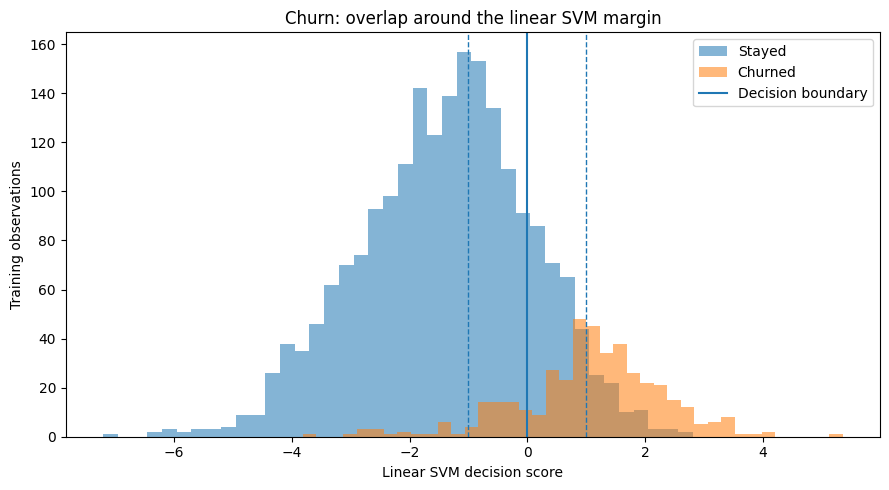

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    train_scores[y_churn_train == 0],
    bins=40,
    alpha=0.55,
    label="Stayed",
)
ax.hist(
    train_scores[y_churn_train == 1],
    bins=40,
    alpha=0.55,
    label="Churned",
)

ax.axvline(-1, linestyle="--", linewidth=1)
ax.axvline(0, linewidth=1.5, label="Decision boundary")
ax.axvline(1, linestyle="--", linewidth=1)
ax.set_xlabel("Linear SVM decision score")
ax.set_ylabel("Training observations")
ax.set_title("Churn: overlap around the linear SVM margin")
ax.legend()
plt.tight_layout()
plt.show()

### Support-vector observation

A substantial share of Churn training observations becomes support vectors. The score distributions also overlap around the decision boundary. That helps explain why a single flat hyperplane is unlikely to separate the two customer groups perfectly.

This is the conceptual reason to test polynomial and RBF kernels rather than simply increasing `C` on the linear model.

## 10. Churn regularization path: what does `C` change?

For the linear Churn model I vary `C` and track four quantities:

- total margin width `2 / ||w||`
- support-vector count
- training balanced accuracy
- validation ROC-AUC

This directly tests the lecture's margin-versus-errors tradeoff.

In [14]:
X_churn_validation = churn_preprocessor.transform(
    churn.iloc[churn_store["validation_idx"]]
)
y_churn_validation = churn.iloc[churn_store["validation_idx"]]["Churn"].astype(int).values

regularization_rows = []
for C in [0.01, 0.1, 1, 10]:
    model = SVC(
        kernel="linear",
        C=C,
        class_weight="balanced",
    ).fit(X_churn_train, y_churn_train)

    train_prediction = model.predict(X_churn_train)
    validation_score = model.decision_function(X_churn_validation)
    validation_prediction = model.predict(X_churn_validation)

    weight_norm = np.linalg.norm(model.coef_)
    total_margin = 2 / weight_norm

    regularization_rows.append({
        "C": C,
        "Total margin width": total_margin,
        "Support vectors": int(model.n_support_.sum()),
        "Training balanced accuracy": balanced_accuracy_score(
            y_churn_train, train_prediction
        ),
        "Validation ROC-AUC": roc_auc_score(
            y_churn_validation, validation_score
        ),
        "Validation balanced accuracy": balanced_accuracy_score(
            y_churn_validation, validation_prediction
        ),
    })

regularization_results = pd.DataFrame(regularization_rows)
display(regularization_results.round(4))

,C,Total margin width,Support vectors,Training balanced accuracy,Validation ROC-AUC,Validation balanced accuracy
0,0.0100,1.3568,1325,0.8192,0.8824,0.8277
1,0.1000,0.8597,1113,0.8222,0.8813,0.8145
2,1.0000,0.5585,1059,0.8282,0.8797,0.8178
3,10.0000,0.4954,1048,0.8353,0.8778,0.8192


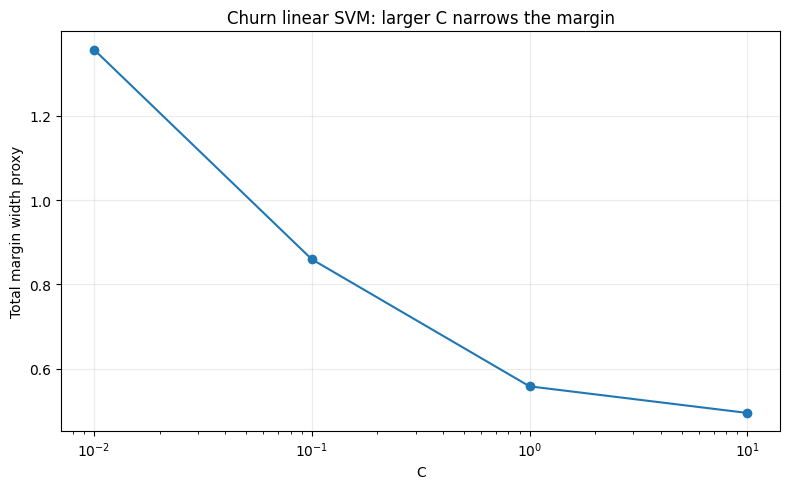

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    regularization_results["C"],
    regularization_results["Total margin width"],
    marker="o",
)
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Total margin width proxy")
ax.set_title("Churn linear SVM: larger C narrows the margin")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

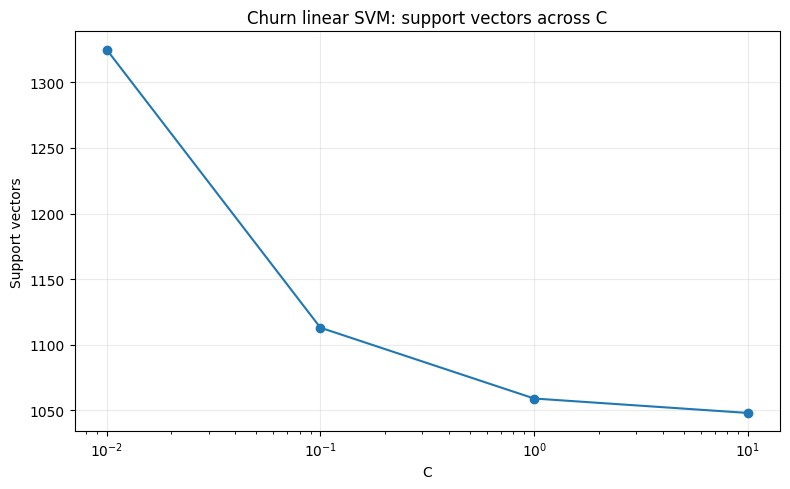

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    regularization_results["C"],
    regularization_results["Support vectors"],
    marker="o",
)
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Support vectors")
ax.set_title("Churn linear SVM: support vectors across C")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Regularization takeaway

The expected tradeoff is visible: larger `C` puts more pressure on classification errors and produces a narrower margin. If validation ranking changes only slightly while the margin shrinks sharply, increasing `C` is not solving the main limitation of the linear boundary.

That is another reason to test a different kernel instead of only pushing `C` upward.

## 11. Five-fold Churn tuning for the depth model

I now tune the three kernel families with five-fold stratified cross-validation on the combined capped Churn development set.

- **Linear:** tune `C`
- **Polynomial:** tune `C` and degree
- **RBF:** tune `C` and `gamma`

ROC-AUC is used for this cross-validation comparison because it evaluates ranking across thresholds. I still report PR-AUC on the final test set because churn is the minority class.

In [17]:
# Rebuild the Churn development/test split from the original split before final testing.

churn_train_validation_idx = np.concatenate([
    churn_store["train_idx"], churn_store["validation_idx"]
])
churn_test_idx = churn_store["test_idx"]

X_churn_dev = churn.iloc[churn_train_validation_idx]
y_churn_dev = churn.iloc[churn_train_validation_idx]["Churn"].astype(int)
X_churn_test = churn.iloc[churn_test_idx]
y_churn_test = churn.iloc[churn_test_idx]["Churn"].astype(int)

def churn_pipeline():
    return Pipeline([
        ("preprocess", make_preprocessor(churn_task)),
        (
            "model",
            SVC(class_weight="balanced"),
        ),
    ])

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

search_specs = {
    "Linear": {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10],
    },
    "Polynomial": [
        {
            "model__kernel": ["poly"],
            "model__C": [10],
            "model__degree": [2, 3],
            "model__gamma": ["scale"],
        }
    ],
    "RBF": [
        {
            "model__kernel": ["rbf"],
            "model__C": [1],
            "model__gamma": [0.1],
        },
        {
            "model__kernel": ["rbf"],
            "model__C": [10],
            "model__gamma": [0.01, 0.1],
        },
    ],
}

searches = {}
tuning_rows = []

for name, grid in search_specs.items():
    search = GridSearchCV(
        estimator=churn_pipeline(),
        param_grid=grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=1,
        return_train_score=True,
    )
    search.fit(X_churn_dev, y_churn_dev)
    searches[name] = search

    best_index = search.best_index_
    tuning_rows.append({
        "Kernel": name,
        "Best parameters": search.best_params_,
        "Mean CV ROC-AUC": search.best_score_,
        "Mean training ROC-AUC": search.cv_results_["mean_train_score"][best_index],
        "Train-CV gap": (
            search.cv_results_["mean_train_score"][best_index]
            - search.best_score_
        ),
    })

tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results.round(4))

,Kernel,Best parameters,Mean CV ROC-AUC,Mean training ROC-AUC,Train-CV gap
0,Linear,"{'model__C': 0.1, 'model__kernel': 'linear'}",0.8915,0.9001,0.0086
1,Polynomial,"{'model__C': 10, 'model__degree': 3, 'model__g...",0.9354,0.9982,0.0628
2,RBF,"{'model__C': 10, 'model__gamma': 0.1, 'model__...",0.9483,1.0000,0.0517


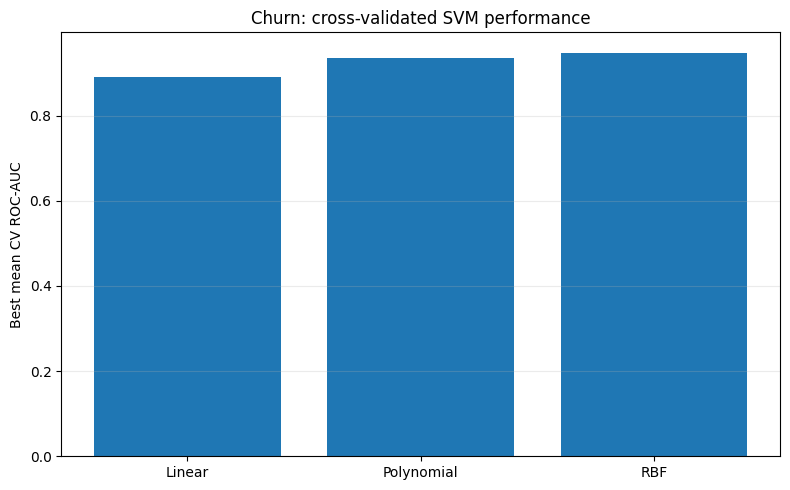

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    tuning_results["Kernel"],
    tuning_results["Mean CV ROC-AUC"],
)
ax.set_ylabel("Best mean CV ROC-AUC")
ax.set_title("Churn: cross-validated SVM performance")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Cross-validation observation

The training-versus-CV gap is important. Nonlinear kernels can fit complicated boundaries, so a very high training score by itself is not reassuring. The better model is the one that keeps the cross-validated ranking strong.

The RBF kernel is the strongest candidate when it improves CV ROC-AUC over the linear model by a meaningful amount and the gain is confirmed on the untouched test set.

## 12. RBF `gamma` sensitivity

For an RBF kernel, `gamma` controls how local each training observation's influence is.

- lower `gamma` creates smoother, broader influence
- higher `gamma` creates more local and flexible boundaries

I summarize the Churn CV surface to see whether the best RBF result depends on one fragile combination or appears in a more stable region.

,C,gamma,CV ROC-AUC,Train ROC-AUC
2,10.0000,0.1000,0.9483,1.0000
0,1.0000,0.1000,0.9469,0.9916
1,10.0000,0.0100,0.9120,0.9427


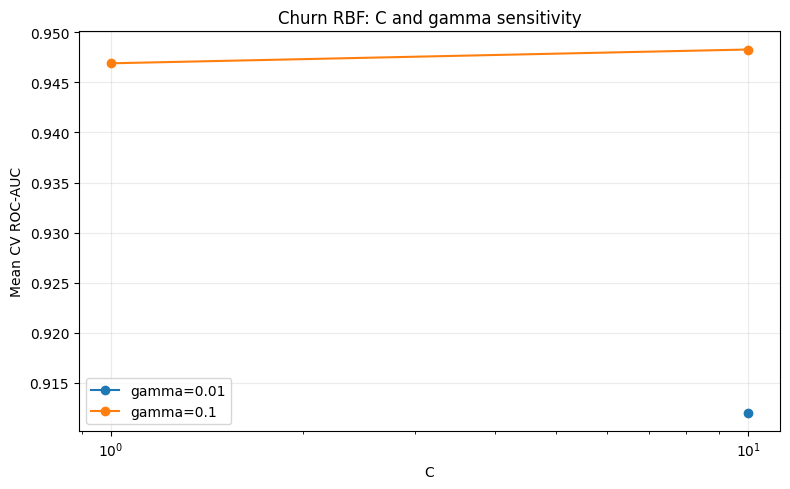

In [19]:
rbf_cv = pd.DataFrame(searches["RBF"].cv_results_)
rbf_view = rbf_cv[[
    "param_model__C",
    "param_model__gamma",
    "mean_test_score",
    "mean_train_score",
]].copy()
rbf_view.columns = ["C", "gamma", "CV ROC-AUC", "Train ROC-AUC"]
rbf_view["C"] = rbf_view["C"].astype(float)
rbf_view["gamma"] = rbf_view["gamma"].astype(float)
display(rbf_view.sort_values("CV ROC-AUC", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for gamma, group in rbf_view.groupby("gamma"):
    group = group.sort_values("C")
    ax.plot(
        group["C"],
        group["CV ROC-AUC"],
        marker="o",
        label=f"gamma={gamma:g}",
    )
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Mean CV ROC-AUC")
ax.set_title("Churn RBF: C and gamma sensitivity")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 13. Final Churn kernel comparison

All Churn tuning decisions are fixed before this step. I refit each best cross-validated kernel on the full development set and evaluate once on the untouched test set.

In [20]:
churn_final_rows = []
churn_final_scores = {}
churn_final_predictions = {}

for name, search in searches.items():
    model = search.best_estimator_
    model.fit(X_churn_dev, y_churn_dev)

    prediction = model.predict(X_churn_test)
    score = model.decision_function(X_churn_test)

    churn_final_rows.append({
        "Kernel": name,
        **class_metrics(y_churn_test, score, prediction),
        "Support vectors": int(model.named_steps["model"].n_support_.sum()),
    })

    churn_final_scores[name] = score
    churn_final_predictions[name] = prediction

churn_final_results = pd.DataFrame(churn_final_rows)
display(churn_final_results.round(4))

,Kernel,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,Support vectors
0,Linear,0.8776,0.6733,0.8045,0.8117,0.4567,0.8226,0.5873,1525
1,Polynomial,0.9326,0.8035,0.9182,0.8844,0.7243,0.8333,0.7750,1001
2,RBF,0.9752,0.9162,0.9518,0.9046,0.8757,0.8333,0.8540,1249


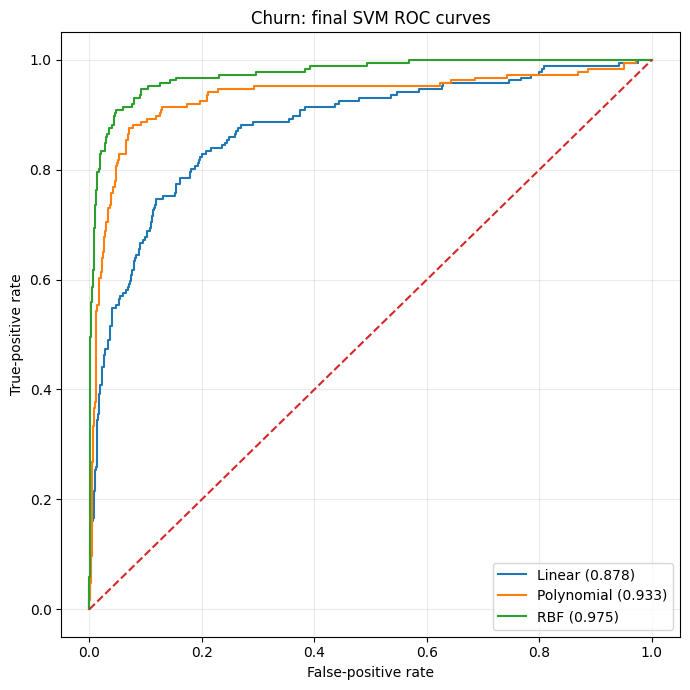

In [21]:
fig, ax = plt.subplots(figsize=(7, 7))
for name, score in churn_final_scores.items():
    fpr, tpr, _ = roc_curve(y_churn_test, score)
    auc_value = roc_auc_score(y_churn_test, score)
    ax.plot(fpr, tpr, label=f"{name} ({auc_value:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate")
ax.set_title("Churn: final SVM ROC curves")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

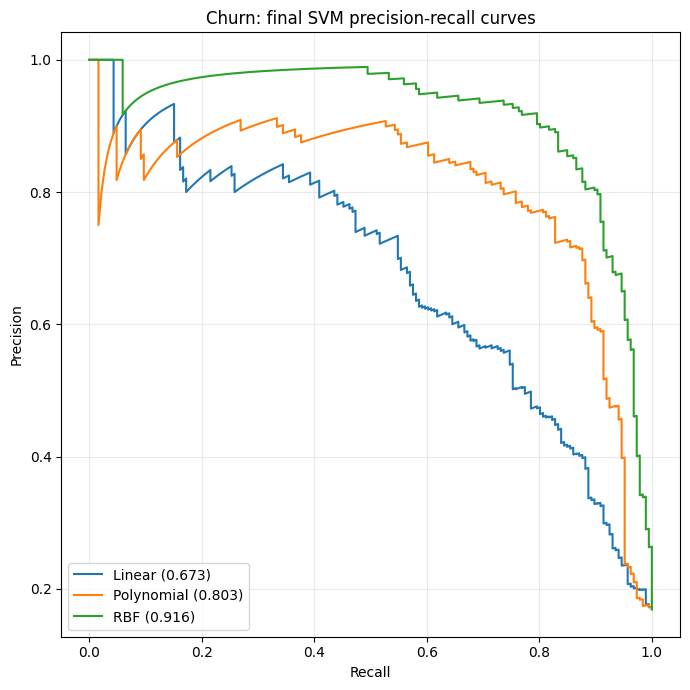

In [22]:
fig, ax = plt.subplots(figsize=(7, 7))
for name, score in churn_final_scores.items():
    precision, recall, _ = precision_recall_curve(y_churn_test, score)
    ap = average_precision_score(y_churn_test, score)
    ax.plot(recall, precision, label=f"{name} ({ap:.3f})")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Churn: final SVM precision-recall curves")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 14. Confusion matrix for the final Churn winner

I inspect classification errors for the kernel with the highest test ROC-AUC. Unlike Week 4 logistic regression, this SVM uses the sign of the decision function rather than a calibrated probability threshold.

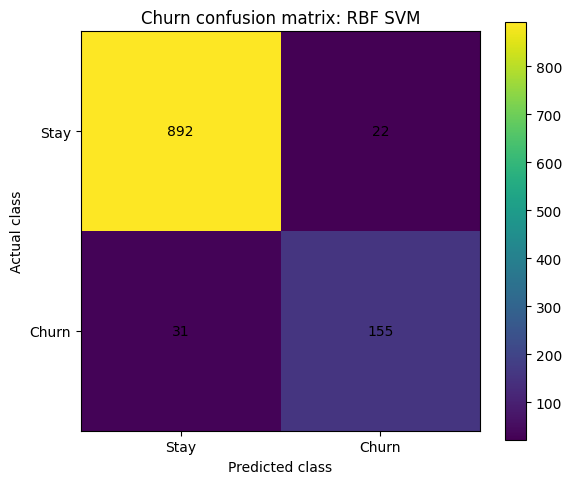

Best Churn kernel: RBF
True negatives:  892
False positives: 22
False negatives: 31
True positives:  155


In [23]:
best_churn_name = (
    churn_final_results
    .sort_values("ROC_AUC", ascending=False)
    .iloc[0]["Kernel"]
)

best_prediction = churn_final_predictions[best_churn_name]
cm = confusion_matrix(y_churn_test, best_prediction)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stay", "Churn"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Stay", "Churn"])

for row in range(2):
    for col in range(2):
        ax.text(col, row, str(cm[row, col]), ha="center", va="center")

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title(f"Churn confusion matrix: {best_churn_name} SVM")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print(f"Best Churn kernel: {best_churn_name}")
print(f"True negatives:  {cm[0,0]}")
print(f"False positives: {cm[0,1]}")
print(f"False negatives: {cm[1,0]}")
print(f"True positives:  {cm[1,1]}")

## 15. What I found

### The datasets do not need the same boundary

The four-table analysis shows why kernel choice should be validated rather than assumed. Some outcomes gain more from a nonlinear boundary than others.

### Churn benefits from nonlinear structure

The depth analysis shows substantial overlap around the linear margin. Increasing `C` narrows the margin, but it does not remove the main limitation of a flat boundary. Polynomial and especially RBF kernels can capture interactions and curved separation that the linear SVM cannot represent directly.

### Support vectors provide a useful diagnostic

When many observations become support vectors, a large share of the data is helping define the boundary. That is consistent with overlapping classes or a complicated separation problem.

### Flexibility has a cost

The RBF model can predict better, but it is harder to explain feature by feature than a linear SVM or logistic regression. I would therefore keep the nonlinear SVM as a strong performance benchmark while using more interpretable models when explanation is the primary requirement.

## 16. How I controlled overfitting

1. Final test partitions were separated before model selection.
2. Behavior was split by customer and Reviews by product.
3. Numeric scaling and categorical encoding were fit within the training workflow.
4. Kernel family and `C` were chosen from validation performance in the four-dataset breadth analysis.
5. The Churn depth model used five-fold stratified cross-validation.
6. Polynomial degree and RBF `gamma` were tuned rather than selected after looking at test results.
7. I compared training and cross-validation ROC-AUC for the nonlinear Churn models.
8. The final Churn test set was evaluated only after tuning was finished.

This is important because nonlinear SVMs can fit training data extremely well without necessarily generalizing.

## 17. Limitations

- Nonlinear SVMs are harder to interpret than logistic regression or a linear SVM.
- The best boundary depends on the ranges searched for `C`, degree, and `gamma`.
- SVC training cost grows quickly with sample size, so Behavior uses a capped sample after leakage-safe grouped splitting.
- Product data are relatively small, so their validation estimates are less stable.
- The Review classifier uses structured metadata, not the full review text.
- The Product and Review binary labels are project-specific analytical definitions.
- SVM decision scores are not calibrated probabilities unless an additional calibration step is used.
- These are predictive associations, not causal effects.

## 18. Course source and reproducibility

### Course sources

- DX799 O1, Week 5 Overview
- Week 5 lesson: **Support Vector Machines, the Kernel Trick, and Regularization**
- Week 5 Jupyter Notebook: **Support Vector Machines**

The course lesson is the basis for the margin, support-vector, kernel-trick, and `C` interpretations used in this notebook.

### External reference

scikit-learn developers, **Support Vector Machines User Guide** and `SVC` documentation  
https://scikit-learn.org/stable/modules/svm.html  
https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

### Reproducibility

- Random seed: 42
- Test share: 20%
- Validation share: 20% of the full data
- Behavior split: grouped by `Customer ID`, followed by capped sampling within partitions
- Review split: grouped by `productASIN`
- Numeric predictors: median imputation plus standardization
- Broad `C` grid: 0.1, 1, 10
- Polynomial degrees: 2 and 3
- Broad RBF gamma values: `scale` and 0.1
- Churn depth tuning: five-fold stratified cross-validation
- Churn RBF gamma grid: 0.01, 0.1, 1
- Churn uses balanced class weights

In [24]:
Path("outputs").mkdir(exist_ok=True)

summary = {
    "week": 5,
    "topic": "Support vector machines, kernels, and regularization",
    "broad_validation": broad_validation.to_dict(orient="records"),
    "final_results": final_results.to_dict(orient="records"),
    "best_family_summary": best_family_summary.to_dict(orient="records"),
    "churn_tuning": tuning_results.to_dict(orient="records"),
    "churn_final": churn_final_results.to_dict(orient="records"),
}

Path("outputs/week5_summary.json").write_text(
    json.dumps(summary, indent=2, default=str)
)

print("Saved outputs/week5_summary.json")

Saved outputs/week5_summary.json
